# Additional Analysis

## Setup

In [6]:
# Imports
import os
import sys
import django
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Django setup
sys.path.insert(0, os.path.abspath("../.."))
os.environ.setdefault("DJANGO_SETTINGS_MODULE", "config.settings")
os.environ.setdefault("DJANGO_ALLOW_ASYNC_UNSAFE", "1")
django.setup()

# Remaining imports
from accounts.models import User
from curriculum.models import Question
from ml_engine.features import FeatureContext
from ml_engine.recommender import predict_correct_probs

# Analysis parameters
BAND_LOW, BAND_HIGH = 0.40, 0.60    # Moderate challenging threshold
TOO_HARD = 0.25                     # Overly challenging threshold

## Difference between original and revised PEAR formula

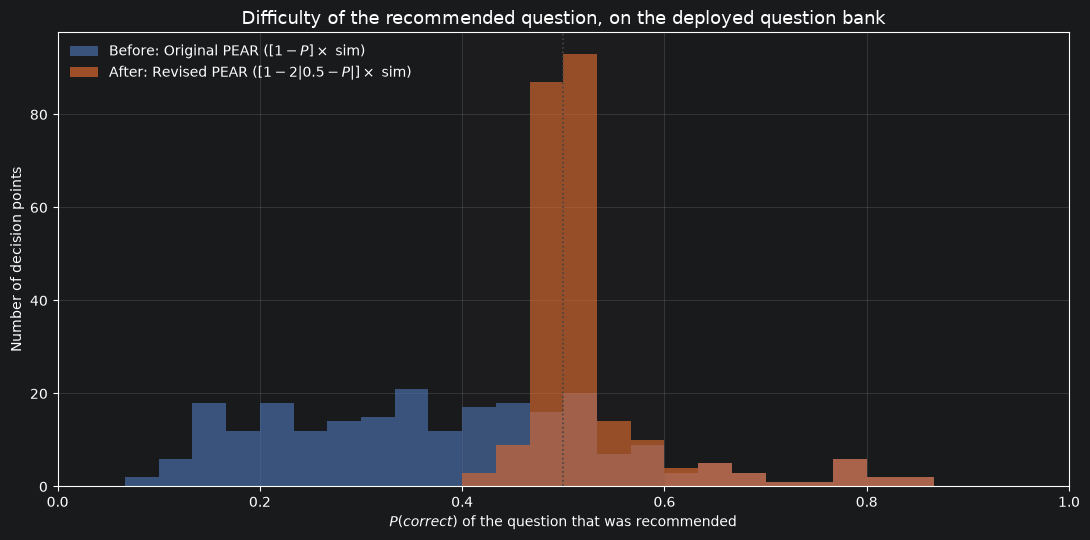

In [7]:
# Retrieve the question bank
bank_questions = list(Question.objects.filter(is_active=True).select_related("micro_skill"))

# Score every question in the bank for every student
bank_rows = []
for student in User.objects.filter(role="student"):
    context = FeatureContext(student)
    for question, p in zip(bank_questions, predict_correct_probs(bank_questions, context)):
        bank_rows.append((student.id, question.micro_skill_id, question.id, p))
bank = pd.DataFrame(bank_rows, columns=["student_id", "skill_id", "question_id", "p_correct"])

# Create pools: One pool = one student attempt on questions within a skill
bank["pool_id"] = bank.groupby(["student_id", "skill_id"]).ngroup()

# Score the questions based on the outcome of the model
bank["original_score"] = 1.0 - bank["p_correct"]
bank["revised_score"] = 1.0 - 2.0 * np.abs(0.5 - bank["p_correct"])

# Select a question from each pool
bank_original = bank.loc[bank.groupby("pool_id")["original_score"].idxmax()].set_index("pool_id")
bank_revised = bank.loc[bank.groupby("pool_id")["revised_score"].idxmax()].set_index("pool_id")
bank_revised = bank_revised.reindex(bank_original.index)

# Plot the histogram (distribution) of questions selected
fig, ax = plt.subplots(figsize=(11, 5.5))
bank_bins = np.linspace(0, 1, 31)
ax.hist(bank_original["p_correct"], bins=bank_bins, alpha=0.65, color="#4c72b0",
        label="Before: Original PEAR ($[1-P] \\times$ sim)")
ax.hist(bank_revised["p_correct"], bins=bank_bins, alpha=0.65, color="#e56d2f",
        label="After: Revised PEAR ($[1-2|0.5-P|] \\times$ sim)")
ax.axvspan(BAND_LOW, BAND_HIGH, color="#444", alpha=0.07)
ax.axvline(0.5, color="#444", ls=":", lw=1.2)
ax.set_title("Difficulty of the recommended question, on the deployed question bank", fontsize=13)
ax.set_xlabel("$P(correct)$ of the question that was recommended")
ax.set_ylabel("Number of decision points")
ax.legend(frameon=False, fontsize=10, loc="upper left")
ax.grid(alpha=0.25); ax.set_axisbelow(True)
ax.set_xlim(0, 1)
fig.tight_layout()
plt.show()